# Proof-of-concept results analysis

This notebook analyses the repeated small-data regression experiment in `results/tables/poc_experiment.csv`. It compares predictive accuracy, probabilistic quality, 90% interval coverage, and measured runtime as the training-set size grows.

The error bars below are 95% *t*-intervals across independent splits. With only three splits, they are useful indicators of variability but should not be interpreted as precise uncertainty estimates.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import t
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

project_root = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "results/tables/poc_experiment.csv").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Run this notebook from inside the project directory.")

results_path = project_root / "results/tables/poc_experiment.csv"
results = pd.read_csv(results_path)
print(f"Loaded {len(results)} rows from {results_path}")

Loaded 84 rows from /Users/paulbahde/Desktop/UncertaintyQuantification/results/tables/poc_experiment.csv


## Validate and inspect the results

Each row should represent one model configuration, split, and requested training size. The checks make schema changes or incomplete experiment output visible before plotting.

In [2]:
required_columns = {
    "dataset", "split", "train_size", "model", "selected_epoch",
    "n_inducing", "final_training_time_seconds",
    "inference_time_seconds", "rmse", "nll", "crps", "coverage_90",
}
missing = required_columns.difference(results.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

key_columns = ["dataset", "split", "train_size", "model"]
if results.duplicated(key_columns).any():
    raise ValueError("Duplicate dataset/split/train-size/model rows found.")

model_order = results["model"].drop_duplicates().tolist()
results["coverage_error_90"] = (results["coverage_90"] - 0.90).abs()
results["total_measured_time_seconds"] = (
    results["final_training_time_seconds"] + results["inference_time_seconds"]
)

overview = pd.Series({
    "datasets": results["dataset"].nunique(),
    "splits": results["split"].nunique(),
    "training sizes": results["train_size"].nunique(),
    "model configurations": results["model"].nunique(),
    "rows": len(results),
    "missing metric/timing values": int(results[["rmse", "nll", "crps", "coverage_90", "final_training_time_seconds", "inference_time_seconds"]].isna().sum().sum()),
})
display(overview.to_frame("value"))
display(results.head())

,value
datasets,1
splits,3
training sizes,4
model configurations,7
rows,84
missing metric/timing values,0


,dataset,split,train_size,selected_epoch,n_inducing,final_training_time_seconds,model,inference_time_seconds,rmse,nll,crps,coverage_90,coverage_error_90,total_measured_time_seconds
0,synthetic,0,25,14.0,NaN,0.0715,exact_gp,0.0073,0.1830,-0.0892,0.1122,1.0000,0.1000,0.0788
1,synthetic,0,25,52.0,16.0,0.2902,sparse_gp_m16,0.0029,0.5761,0.8669,0.3358,0.9667,0.0667,0.2931
2,synthetic,0,25,55.0,25.0,0.2913,sparse_gp_m64,0.0033,0.5072,0.7213,0.2872,1.0000,0.1000,0.2946
3,synthetic,0,25,55.0,25.0,0.3021,sparse_gp_m256,0.0042,0.5072,0.7213,0.2872,1.0000,0.1000,0.3064
4,synthetic,0,25,157.0,NaN,0.6232,deep_ensemble,0.0007,1.0693,1.4699,0.6276,0.9833,0.0833,0.6239


## Aggregate results

Means are accompanied by standard deviations and 95% confidence intervals across splits. These intervals quantify split-to-split variation, not uncertainty for individual predictions.

In [3]:
group_columns = ["dataset", "train_size", "model"]
analysis_metrics = [
    "rmse", "nll", "crps", "coverage_90", "coverage_error_90",
    "final_training_time_seconds", "inference_time_seconds",
]

def aggregate_metric(frame, metric):
    summary = (
        frame.groupby(group_columns, observed=True)[metric]
        .agg(mean="mean", std="std", n="count")
        .reset_index()
    )
    summary["sem"] = summary["std"] / np.sqrt(summary["n"])
    summary["ci95"] = t.ppf(0.975, summary["n"] - 1) * summary["sem"]
    summary.loc[summary["n"] < 2, "ci95"] = np.nan
    return summary

aggregated = pd.concat(
    [aggregate_metric(results, metric).assign(metric=metric) for metric in analysis_metrics],
    ignore_index=True,
)

summary_table = (
    results.groupby(group_columns, observed=True)[analysis_metrics]
    .mean()
    .reset_index()
    .sort_values(["dataset", "train_size", "rmse"])
)
display(summary_table)

,dataset,train_size,model,rmse,nll,crps,coverage_90,coverage_error_90,final_training_time_seconds,inference_time_seconds
2,synthetic,25,exact_gp,0.2005,-0.0598,0.1206,0.9722,0.0722,0.0716,0.0054
4,synthetic,25,sparse_gp_m16,0.4258,0.6149,0.2509,0.9889,0.0889,1.0759,0.0034
5,synthetic,25,sparse_gp_m256,0.4482,0.6095,0.2566,0.9944,0.0944,1.0005,0.0039
6,synthetic,25,sparse_gp_m64,0.4482,0.6095,0.2566,0.9944,0.0944,1.0201,0.0043
1,synthetic,25,dkl,0.5015,0.9830,0.3155,0.7944,0.2056,0.2532,0.0046
0,synthetic,25,deep_ensemble,0.9738,1.4273,0.5748,0.9944,0.0944,0.7926,0.0007
3,synthetic,25,mc_dropout,1.2371,1.6427,0.7507,0.9444,0.0556,0.1616,0.0036
9,synthetic,50,exact_gp,0.2021,-0.1497,0.1158,0.9222,0.0333,0.0827,0.0041
11,synthetic,50,sparse_gp_m16,0.2150,0.3126,0.1522,1.0000,0.1000,1.1920,0.0036
12,synthetic,50,sparse_gp_m256,0.2257,0.3354,0.1574,1.0000,0.1000,1.2479,0.0037


## Predictive performance versus training size

Lower is better for RMSE, NLL, and CRPS. For coverage, values closer to the dashed 0.90 reference are better; coverage above 0.90 may indicate conservative intervals, while coverage below 0.90 may indicate overconfidence.

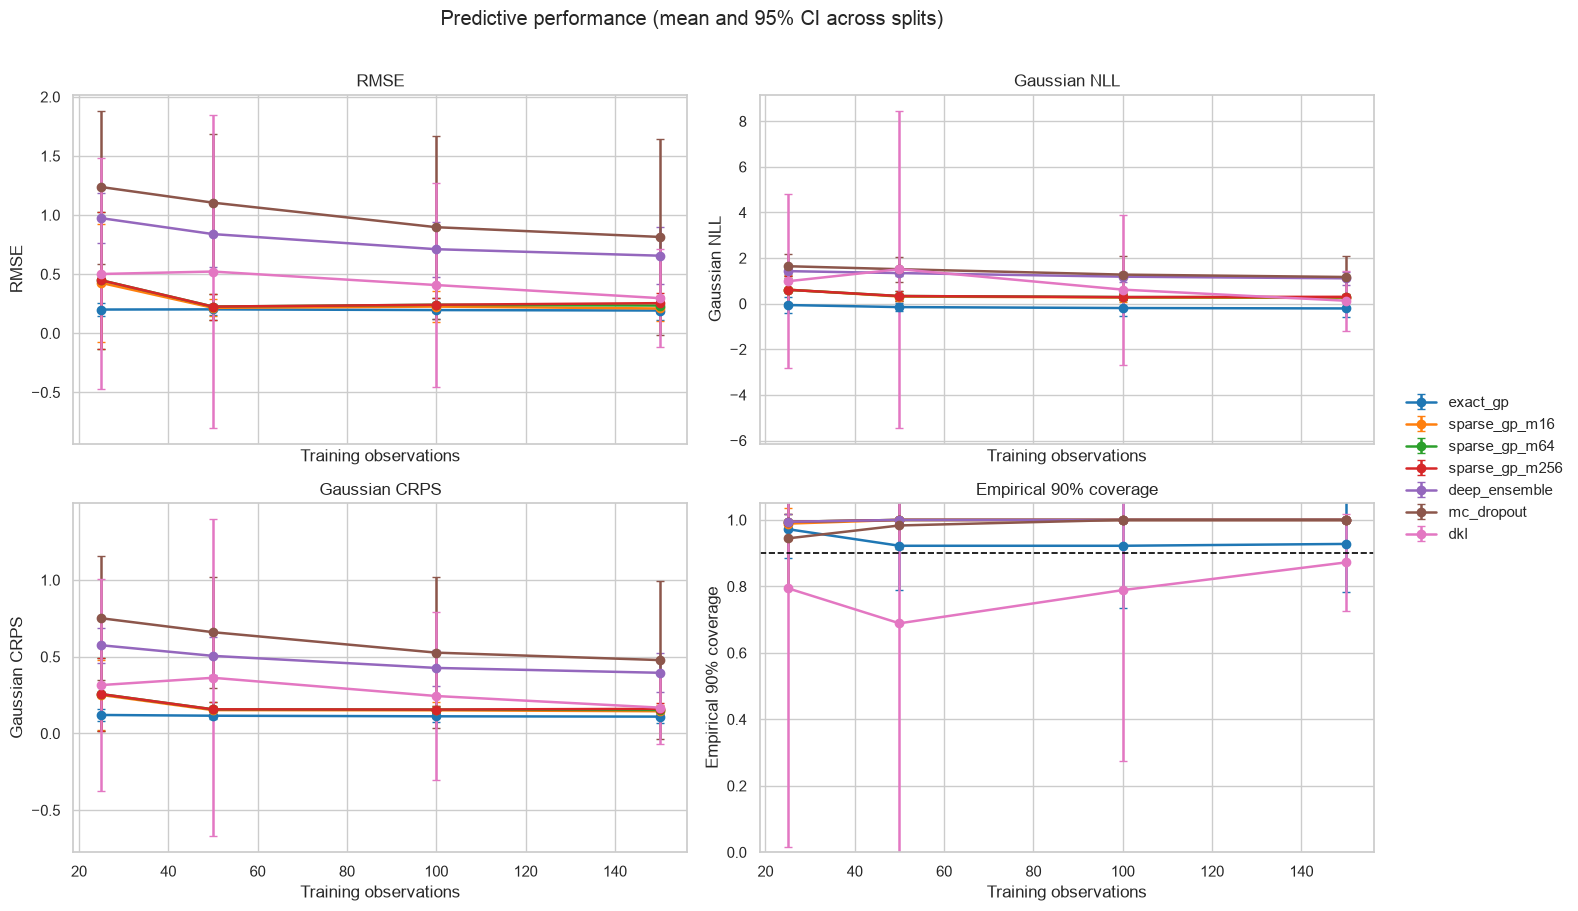

In [4]:
metric_labels = {
    "rmse": "RMSE",
    "nll": "Gaussian NLL",
    "crps": "Gaussian CRPS",
    "coverage_90": "Empirical 90% coverage",
}
palette = dict(zip(model_order, sns.color_palette("tab10", len(model_order))))

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, metric in zip(axes.flat, metric_labels):
    metric_data = aggregated[aggregated["metric"] == metric]
    for model in model_order:
        group = metric_data[metric_data["model"] == model].sort_values("train_size")
        ax.errorbar(
            group["train_size"], group["mean"], yerr=group["ci95"],
            marker="o", capsize=3, linewidth=1.8, label=model, color=palette[model],
        )
    if metric == "coverage_90":
        ax.axhline(0.90, color="black", linestyle="--", linewidth=1.2, label="nominal 90%")
        ax.set_ylim(0, 1.05)
    ax.set_title(metric_labels[metric])
    ax.set_xlabel("Training observations")
    ax.set_ylabel(metric_labels[metric])

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
fig.suptitle("Predictive performance (mean and 95% CI across splits)", y=1.01)
fig.tight_layout()
plt.show()

## Runtime comparison

Final training time covers only retraining on the complete requested subset after the epoch count was selected. It excludes validation-based epoch selection and feature scaling. Inference time covers prediction over the complete held-out test set and excludes metric calculation. Logarithmic axes make large differences visible.

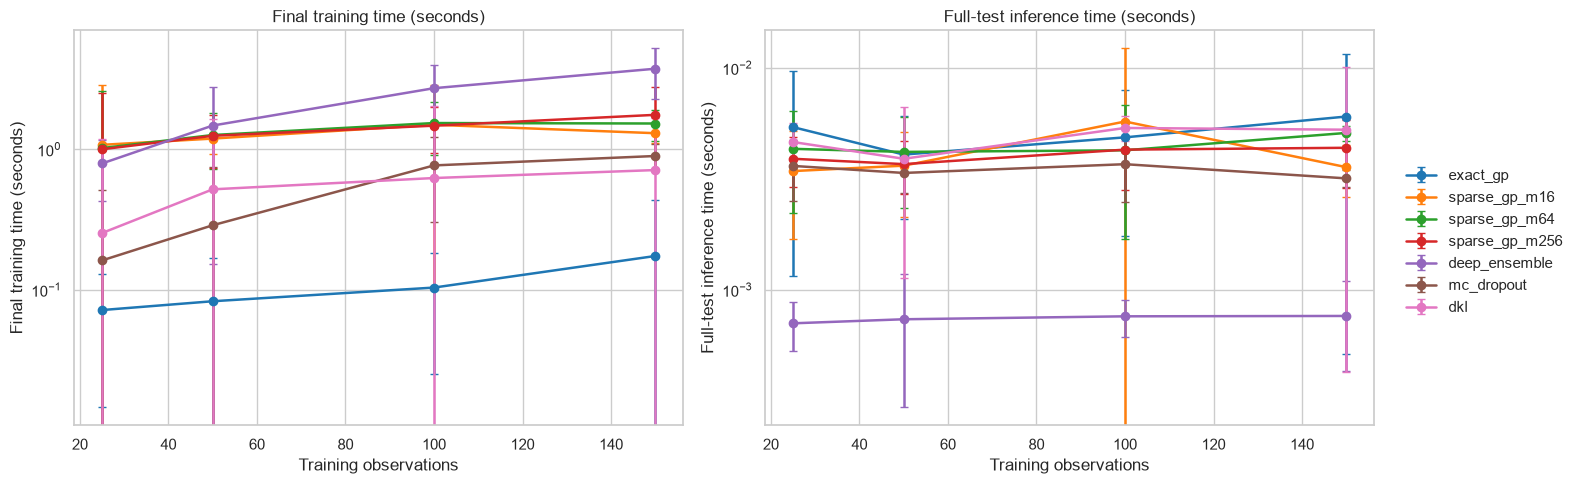

In [5]:
timing_labels = {
    "final_training_time_seconds": "Final training time (seconds)",
    "inference_time_seconds": "Full-test inference time (seconds)",
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, timing_labels):
    metric_data = aggregated[aggregated["metric"] == metric]
    for model in model_order:
        group = metric_data[metric_data["model"] == model].sort_values("train_size")
        ax.errorbar(
            group["train_size"], group["mean"], yerr=group["ci95"],
            marker="o", capsize=3, linewidth=1.8, label=model, color=palette[model],
        )
    ax.set_yscale("log")
    ax.set_xlabel("Training observations")
    ax.set_ylabel(timing_labels[metric])
    ax.set_title(timing_labels[metric])

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
fig.tight_layout()
plt.show()

## Performance–cost trade-off at the largest training size

This view compares average RMSE with final training time. A desirable method lies toward the lower-left. It is descriptive rather than a hardware-independent complexity comparison.

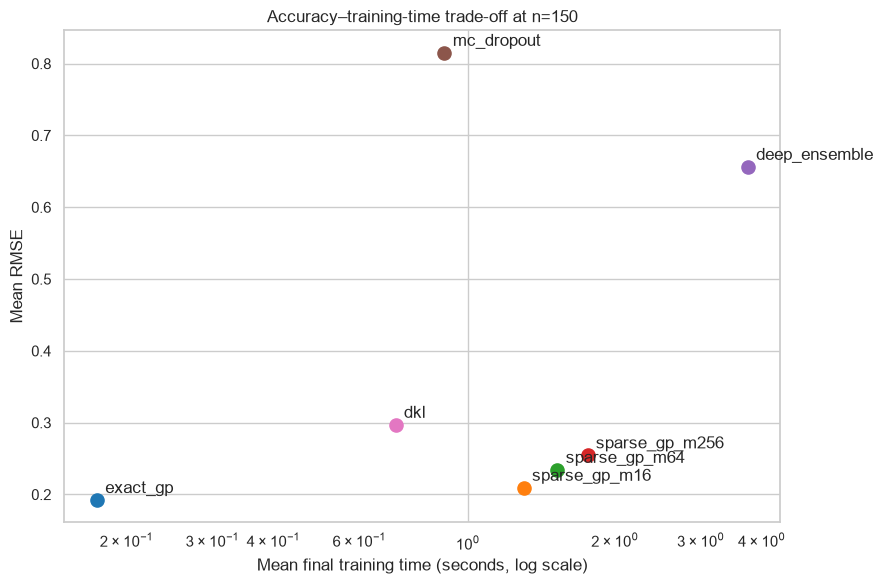

,model,rmse,crps,coverage_error,training_time,inference_time
2,exact_gp,0.1923,0.1099,0.05,0.1738,0.0060
4,sparse_gp_m16,0.2094,0.1450,0.10,1.3020,0.0036
6,sparse_gp_m64,0.2344,0.1534,0.10,1.5266,0.0051
5,sparse_gp_m256,0.2546,0.1605,0.10,1.7596,0.0044
1,dkl,0.2971,0.1685,0.05,0.7112,0.0053
0,deep_ensemble,0.6562,0.3955,0.10,3.7494,0.0008
3,mc_dropout,0.8150,0.4783,0.10,0.8958,0.0032


In [6]:
largest_size = int(results["train_size"].max())
tradeoff = (
    results[results["train_size"] == largest_size]
    .groupby("model", observed=True)
    .agg(
        rmse=("rmse", "mean"),
        crps=("crps", "mean"),
        coverage_error=("coverage_error_90", "mean"),
        training_time=("final_training_time_seconds", "mean"),
        inference_time=("inference_time_seconds", "mean"),
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 6))
for row in tradeoff.itertuples():
    ax.scatter(row.training_time, row.rmse, s=90, color=palette[row.model])
    ax.annotate(row.model, (row.training_time, row.rmse), xytext=(6, 5), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("Mean final training time (seconds, log scale)")
ax.set_ylabel("Mean RMSE")
ax.set_title(f"Accuracy–training-time trade-off at n={largest_size}")
plt.tight_layout()
plt.show()
display(tradeoff.sort_values("rmse"))

## Split-wise method rankings

Ranking within each split and training size avoids letting metrics with different numerical scales dominate. Lower average rank is better. Coverage is ranked by absolute distance from the nominal 0.90 level. Ties receive their average rank.

,train_size,model,rmse_rank,nll_rank,crps_rank,coverage_error_90_rank,mean_rank
2,25,exact_gp,1.6667,1.0000,1.0000,3.1667,1.7083
5,25,sparse_gp_m256,2.8333,3.5000,3.5000,4.5000,3.5833
6,25,sparse_gp_m64,2.8333,3.5000,3.5000,4.5000,3.5833
1,25,dkl,3.6667,3.6667,3.3333,4.1667,3.7083
4,25,sparse_gp_m16,4.0000,4.0000,4.0000,4.5000,4.1250
0,25,deep_ensemble,6.0000,5.6667,5.6667,4.8333,5.5417
3,25,mc_dropout,7.0000,6.6667,7.0000,2.3333,5.7500
9,50,exact_gp,2.0000,1.0000,1.0000,1.5000,1.3750
11,50,sparse_gp_m16,2.6667,2.6667,3.3333,4.8333,3.3750
8,50,dkl,4.3333,3.6667,3.6667,3.5000,3.7917


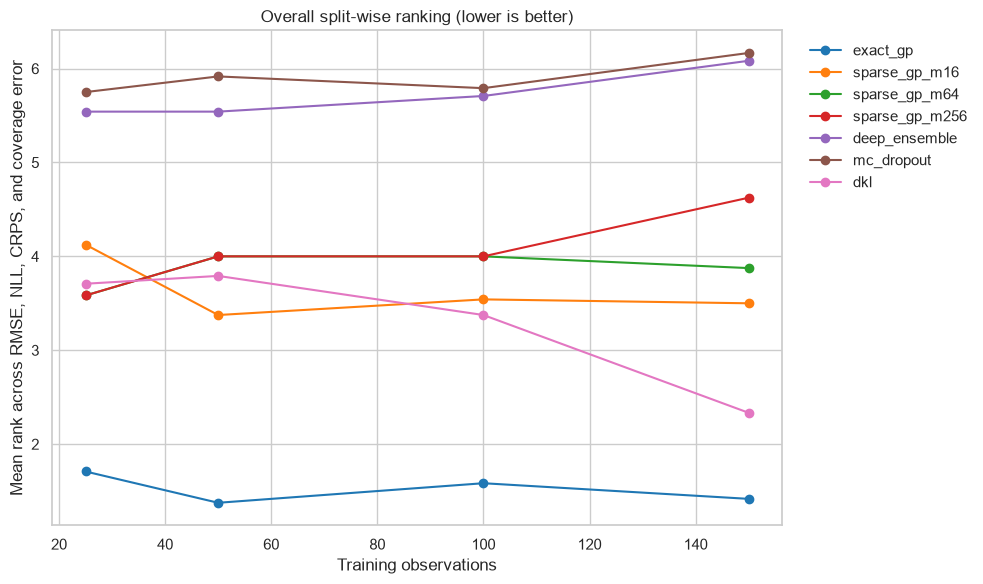

In [7]:
rank_metrics = ["rmse", "nll", "crps", "coverage_error_90"]
ranked = results.copy()
for metric in rank_metrics:
    ranked[f"{metric}_rank"] = ranked.groupby(
        ["dataset", "split", "train_size"]
    )[metric].rank(method="average", ascending=True)

rank_columns = [f"{metric}_rank" for metric in rank_metrics]
ranked["mean_rank"] = ranked[rank_columns].mean(axis=1)
rank_summary = (
    ranked.groupby(["train_size", "model"], observed=True)[rank_columns + ["mean_rank"]]
    .mean()
    .reset_index()
    .sort_values(["train_size", "mean_rank"])
)
display(rank_summary)

plt.figure(figsize=(10, 6))
for model in model_order:
    group = rank_summary[rank_summary["model"] == model].sort_values("train_size")
    plt.plot(group["train_size"], group["mean_rank"], marker="o", label=model, color=palette[model])
plt.xlabel("Training observations")
plt.ylabel("Mean rank across RMSE, NLL, CRPS, and coverage error")
plt.title("Overall split-wise ranking (lower is better)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

## Automatically generated headline results

These statements report the best observed mean at each training size. They are descriptive: overlapping confidence intervals and the small number of splits mean that a winner should not automatically be interpreted as statistically superior.

In [8]:
for train_size in sorted(results["train_size"].unique()):
    current = summary_table[summary_table["train_size"] == train_size]
    print(f"Training size {train_size}:")
    for metric in ["rmse", "nll", "crps", "coverage_error_90"]:
        winner = current.loc[current[metric].idxmin()]
        print(f"  best mean {metric}: {winner['model']} ({winner[metric]:.4f})")
    print()

Training size 25:
  best mean rmse: exact_gp (0.2005)
  best mean nll: exact_gp (-0.0598)
  best mean crps: exact_gp (0.1206)
  best mean coverage_error_90: mc_dropout (0.0556)

Training size 50:
  best mean rmse: exact_gp (0.2021)
  best mean nll: exact_gp (-0.1497)
  best mean crps: exact_gp (0.1158)
  best mean coverage_error_90: exact_gp (0.0333)

Training size 100:
  best mean rmse: exact_gp (0.1961)
  best mean nll: exact_gp (-0.1908)
  best mean crps: exact_gp (0.1119)
  best mean coverage_error_90: exact_gp (0.0556)

Training size 150:
  best mean rmse: exact_gp (0.1923)
  best mean nll: exact_gp (-0.2088)
  best mean crps: exact_gp (0.1099)
  best mean coverage_error_90: exact_gp (0.0500)



## Interpretation notes and next analyses

- Three splits are enough for a pipeline check, but not for strong inferential claims. Increase the number of independent splits for the final study.
- Coverage at one nominal level cannot reveal the full calibration shape. Saving per-observation predictive means and standard deviations would enable calibration curves and standardized-residual diagnostics.
- The current runtime values are wall-clock measurements on one machine. Report hardware and software versions, and consider repeated timing runs if small runtime differences matter.
- Sparse-GP configurations are evaluated only when the training size is strictly larger than the requested inducing-point count. Missing small-size rows are therefore intentional.
- Final conclusions should consider predictive quality, calibration, and computation together rather than selecting a method from one metric alone.